# 3 — Preprocessing


## Imports


In [39]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import wfdb
from scipy.signal import butter, sosfiltfilt

import matplotlib.pyplot as plt
from IPython.display import display


## Configuration


In [40]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}

## Artifact helpers


In [41]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


## Patient leakage checks


In [42]:
def validate_split(beats):
    if set(beats.split) != {'train', 'validation', 'test'}:
        raise ValueError('ต้องมีเพียง train/validation/test')
    if beats.groupby('patient_group').split.nunique().max() != 1:
        raise ValueError('พบ patient leakage')
    for name, part in beats.groupby('split'):
        if set(part.class_id) != set(range(5)):
            raise ValueError(f'{name} มีคลาสไม่ครบ 5; หยุดก่อนฝึก ห้ามแก้ split จากคะแนนโมเดล')
    paired = beats[beats.record_id.isin(['201', '202'])]
    if not paired.empty and (paired.patient_group.nunique() != 1 or paired.split.nunique() != 1):
        raise ValueError('201/202 ต้องเป็นผู้ป่วยกลุ่มเดียวและชุดเดียวกัน')

## Lead selection and record reading


In [43]:
def choose_lead(names):
    for name in PREPROCESSING['leads']:
        if name in names:
            return names.index(name), name
    raise ValueError(f'ไม่มี lead MLII หรือ V5: {names}')

def read_record(path):
    record = wfdb.rdrecord(str(path))
    if record.fs != PREPROCESSING['fs']:
        raise ValueError(f'ต้องการ 360 Hz แต่พบ {record.fs}')
    index, lead = choose_lead(record.sig_name)
    signal = np.asarray(record.p_signal[:, index], dtype=np.float64)
    if len(signal) != record.sig_len or not np.isfinite(signal).all():
        # ไม่ filter ข้าม NaN เพราะจะกระจายความเสียหายไปทั้ง record
        raise ValueError(f'{path}: signal ไม่ครบหรือมี NaN/Inf ต้องตรวจสอบก่อน')
    return signal, lead

## Filtering and segmentation


In [44]:
def segment(signal, samples):
    samples = np.asarray(samples, dtype=np.int64)
    if samples.ndim != 1 or np.any(np.diff(samples) <= 0):
        raise ValueError('ตำแหน่ง heartbeat ต้องเรียงและไม่ซ้ำ')
    if np.any(samples < 0) or np.any(samples >= len(signal)):
        raise ValueError('ตำแหน่ง annotation อยู่นอก signal')
    sos = butter(4, [0.5, 40], btype='bandpass', fs=360, output='sos')
    filtered = sosfiltfilt(sos, signal)
    valid = (samples >= 90) & (samples + 162 <= len(signal))
    waves = np.array([filtered[r - 90:r + 162] for r in samples[valid]], dtype=np.float32)
    if not len(waves):
        raise ValueError('ไม่มี heartbeat ที่ตัดหน้าต่าง 252 samples ได้')
    if waves.shape[1] != 252 or not np.isfinite(waves).all():
        raise ValueError('waveform หลัง filter ใช้งานไม่ได้')
    return waves, valid

## RR context


In [45]:
def rr_features(samples):
    # คำนวณบนลำดับ beats ทั้ง record ก่อนตัด boundary beats ทิ้ง
    intervals = np.diff(samples) / 360.0
    previous = np.r_[np.nan, intervals]
    following = np.r_[intervals, np.nan]
    trailing = pd.Series(previous).rolling(10, min_periods=1).mean().to_numpy()
    return np.column_stack([previous, following, previous / following, trailing])

## Verify input artifacts


In [46]:
raw = RAW
split = read_json(DATA / 'split.json')
audit_info = read_json(DATA / 'audit.json')
if sha256(DATA / 'audit.json') != split['audit_hash']:
    raise ValueError('audit เปลี่ยนหลัง split')
for name, expected in audit_info['files'].items():
    if sha256(raw / name) != expected:
        raise ValueError(f'raw file เปลี่ยน: {name}')
inventory = pd.read_parquet(DATA / 'split_inventory.parquet')

## Process each record


In [47]:
chunks, waves, rrs, exclusions = [], [], [], []
for record_id, part in inventory.groupby('record_id', sort=True):
    part = part.sort_values('r_sample').reset_index(drop=True)
    signal, _ = read_record(raw / record_id)
    samples = part.r_sample.to_numpy()
    wave, valid = segment(signal, samples)
    rr = rr_features(samples)[valid]
    exclusions.extend(part.loc[~valid, ['beat_id', 'record_id']].assign(reason='window_boundary').to_dict('records'))
    chunks.append(part.loc[valid].copy())
    waves.append(wave)
    rrs.append(rr)

## Class N resampling by split

Read the settings saved by notebook 1. Compute RR on complete beat sequences first, then apply one shared selection to metadata, waveforms and RR arrays. N beats are sampled independently within each configured split. Other classes and patient assignments stay unchanged.


In [48]:
def undersample_n_by_split(meta, wave, rr, config):
    # RR is computed before sampling; one shared mask preserves beat alignment.
    if len(meta) != len(wave) or len(meta) != len(rr) or meta.beat_id.duplicated().any():
        raise ValueError('Invalid beat alignment before resampling')
    if config['method'] != 'random_undersampling' or config['class_label'] != 'N':
        raise ValueError('Only random undersampling of class N is supported')
    ratio = float(config['n_to_largest_other_ratio'])
    if not np.isfinite(ratio) or ratio <= 0:
        raise ValueError('n_to_largest_other_ratio must be finite and positive')
    split_names = ['train', 'validation', 'test']
    enabled_splits = config['splits']
    if len(set(enabled_splits)) != len(enabled_splits) or not set(enabled_splits).issubset(split_names):
        raise ValueError('Resampling splits must be unique train/validation/test names')
    n_id = CLASSES.index('N')
    keep = np.ones(len(meta), dtype=bool)
    summaries = {}
    for split_index, name in enumerate(split_names):
        mask = meta.split.eq(name).to_numpy()
        counts = meta.loc[mask, 'class_id'].value_counts().reindex(range(len(CLASSES)), fill_value=0)
        if (counts == 0).any():
            raise ValueError(f'{name} must contain all five classes before resampling')
        n_positions = np.flatnonzero(mask & meta.class_id.eq(n_id).to_numpy())
        target = min(len(n_positions), max(1, int(np.ceil(ratio * counts.drop(n_id).max()))))
        if config['enabled'] and name in enabled_splits and target < len(n_positions):
            # A separate deterministic stream keeps each split's draw independent.
            rng = np.random.default_rng(np.random.SeedSequence([config['seed'], split_index]))
            chosen = rng.choice(n_positions, size=target, replace=False)
            keep[n_positions] = False
            keep[chosen] = True
        summaries[name] = {
            'counts_before': {label: int(counts[i]) for i, label in enumerate(CLASSES)},
            'counts_after': {
                label: int((mask & keep & meta.class_id.eq(i).to_numpy()).sum())
                for i, label in enumerate(CLASSES)
            },
            'removed_n_beats': int((mask & ~keep).sum()),
        }
    summary = {'configuration': dict(config), 'splits': summaries,
               'removed_n_beats': int((~keep).sum())}
    removed = meta.loc[~keep, ['beat_id', 'record_id', 'patient_group', 'class_id', 'split']].copy()
    return meta.loc[keep].reset_index(drop=True), wave[keep], rr[keep], removed, summary


In [49]:
meta = pd.concat(chunks, ignore_index=True)
wave = np.concatenate(waves)
rr = np.concatenate(rrs)
validate_split(meta)
meta, wave, rr, removed_n, resampling_info = undersample_n_by_split(
    meta, wave, rr, audit_info['resampling'],
)
validate_split(meta)
resampling_summary = pd.DataFrame([
    {'Split': name, 'Class': label,
     'Before': details['counts_before'][label],
     'After': details['counts_after'][label]}
    for name, details in resampling_info['splits'].items()
    for label in CLASSES
]).set_index(['Split', 'Class'])
print('Class counts before and after resampling by split:')
display(resampling_summary.style.format({'Before': '{:,}', 'After': '{:,}'}))
print(f"Removed N beats across all splits: {resampling_info['removed_n_beats']:,}")


Class counts before and after resampling by split:


Removed N beats across all splits: 80,931


## Fit normalization on Train


In [50]:
# Fit เฉพาะ Train; validation/test ได้ transform ด้วยค่าเดียวกัน
train_wave = wave[meta.split.eq('train').to_numpy()]
mean, std = float(train_wave.mean(dtype=np.float64)), float(train_wave.std(dtype=np.float64))
if std <= 1e-12:
    raise ValueError('Train waveform ไม่มี variance')
state = {**PREPROCESSING, 'mean': mean, 'std': std, 'split_hash': split['split_hash'],
         'audit_hash': split['audit_hash'], 'classes': CLASSES, 'label_map': LABEL_MAP,
         'resampling': resampling_info}

## Save each partition


In [51]:
for name in ['train', 'validation', 'test']:
    mask = meta.split.eq(name).to_numpy()
    folder = DATA / name
    folder.mkdir(parents=True, exist_ok=True)
    selected = meta.loc[mask].copy().reset_index(drop=True)
    selected['waveform_index'] = np.arange(len(selected))
    selected.to_parquet(folder / 'metadata.parquet', index=False)
    np.save(folder / 'waveforms.npy', ((wave[mask] - mean) / std).astype(np.float32))
    np.save(folder / 'rr.npy', rr[mask])
pd.DataFrame(exclusions, columns=['beat_id', 'record_id', 'reason']).to_csv(DATA / 'excluded_beats.csv', index=False)
removed_n.to_csv(DATA / 'undersampled_n_beats.csv', index=False)
resampling_summary.to_csv(DATA / 'resampling_summary.csv')
write_json(DATA / 'resampling.json', resampling_info)
write_json(DATA / 'preprocessing.json', state)
meta.groupby(['split', 'class_id']).size().unstack(fill_value=0)

class_id,0,1,2,3,4
split,,,,,
test,2062,279,772,25,2062
train,5799,2254,5799,755,4176
validation,1802,248,664,22,1802


## Visualize remaining classes and splits

Counts below come from the saved partition metadata after window-boundary exclusions and N undersampling within each configured split. Run Imports and Configuration, then these visualization cells to inspect existing results without repeating preprocessing. All-splits counts include resampled Validation/Test distributions; the Train panel shows the training distribution after resampling. Beat shares no longer follow 80/10/10 after undersampling.


In [52]:
split_order = ['train', 'validation', 'test']
split_labels = ['Train', 'Validation', 'Test']
split_colors = {'train': '#0072B2', 'validation': '#E69F00', 'test': '#009E73'}
class_colors = {'N': '#0072B2', 'S': '#E69F00', 'V': '#009E73',
                'F': '#CC79A7', 'Q': '#D55E00'}
# Read the final saved metadata, not the pre-resampling split summary.
processed_meta = pd.concat([
    pd.read_parquet(DATA / name / 'metadata.parquet')
    for name in split_order
], ignore_index=True)
split_counts = processed_meta.groupby('split').agg(
    patients=('patient_group', 'nunique'), beats=('beat_id', 'size'),
).reindex(split_order)
class_by_split = pd.crosstab(processed_meta.split, processed_meta.class_id).reindex(
    index=split_order, columns=range(len(CLASSES)), fill_value=0,
)
class_by_split.columns = [str(i) for i in range(len(CLASSES))]
split_counts = split_counts.join(class_by_split)
class_columns = [str(i) for i in range(len(CLASSES))]
split_overview = split_counts[['patients', 'beats']].copy()
split_overview['patient_share_pct'] = split_overview['patients'] / split_overview['patients'].sum() * 100
split_overview['beat_share_pct'] = split_overview['beats'] / split_overview['beats'].sum() * 100
split_overview = split_overview.join(split_counts[class_columns].rename(columns=dict(zip(class_columns, CLASSES))))
display(split_overview.style.format({
    **{column: '{:,}' for column in ['patients', 'beats', *CLASSES]},
    'patient_share_pct': '{:.2f}', 'beat_share_pct': '{:.2f}',
}))



,patients,beats,patient_share_pct,beat_share_pct,N,S,V,F,Q
split,,,,,,,,,
train,37,"18,783",78.72,65.86,"5,799","2,254","5,799",755,"4,176"
validation,5,"4,538",10.64,15.91,"1,802",248,664,22,"1,802"
test,5,"5,200",10.64,18.23,"2,062",279,772,25,"2,062"


### Remaining beats in each class


Class,All splits,Train,All splits (%),Train (%)
N,"9,663","5,799",33.88,30.87
S,"2,781","2,254",9.75,12.00
V,"7,235","5,799",25.37,30.87
F,802,755,2.81,4.02
Q,"8,040","4,176",28.19,22.23


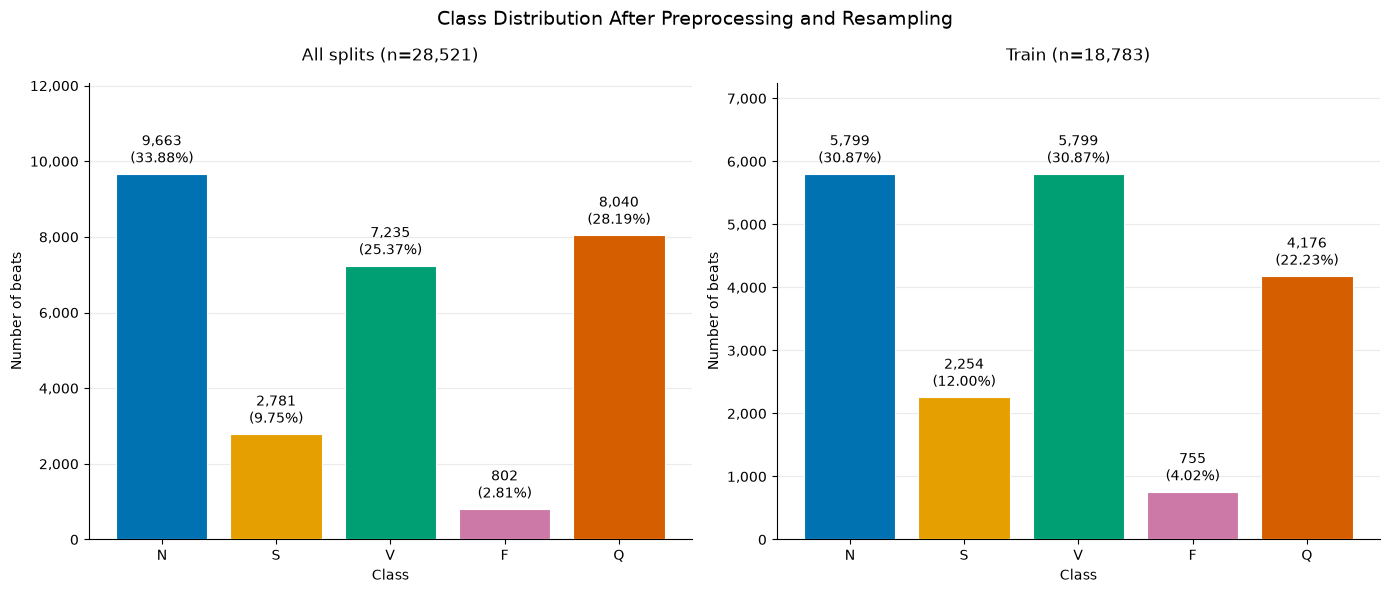

In [53]:
class_summary = pd.DataFrame({
    'Class': CLASSES,
    'All splits': split_counts[class_columns].sum().to_numpy(dtype=int),
    'Train': split_counts.loc['train', class_columns].to_numpy(dtype=int),
})
for column in ['All splits', 'Train']:
    total = int(class_summary[column].sum())
    class_summary[f'{column} (%)'] = class_summary[column] / total * 100 if total else 0.0
display(class_summary.style.format({
    'All splits': '{:,}', 'Train': '{:,}',
    'All splits (%)': '{:.2f}', 'Train (%)': '{:.2f}',
}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column in zip(axes, ['All splits', 'Train']):
    values = class_summary[column].to_numpy()
    percentages = class_summary[f'{column} (%)'].to_numpy()
    bars = ax.bar(CLASSES, values, color=[class_colors[label] for label in CLASSES],
                  edgecolor='white', linewidth=0.8, zorder=3)
    ax.bar_label(bars, labels=[f'{count:,}\n({percentage:.2f}%)'
                              for count, percentage in zip(values, percentages)],
                 padding=5, fontsize=10)
    ax.set_title(f'{column} (n={int(values.sum()):,})', pad=16)
    ax.set_xlabel('Class')
    ax.set_ylabel('Number of beats')
    ax.set_ylim(0, max(values.max() * 1.25, 1))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Class Distribution After Preprocessing and Resampling', fontsize=14)
fig.tight_layout()
plt.show()


### Remaining patients and beats by split


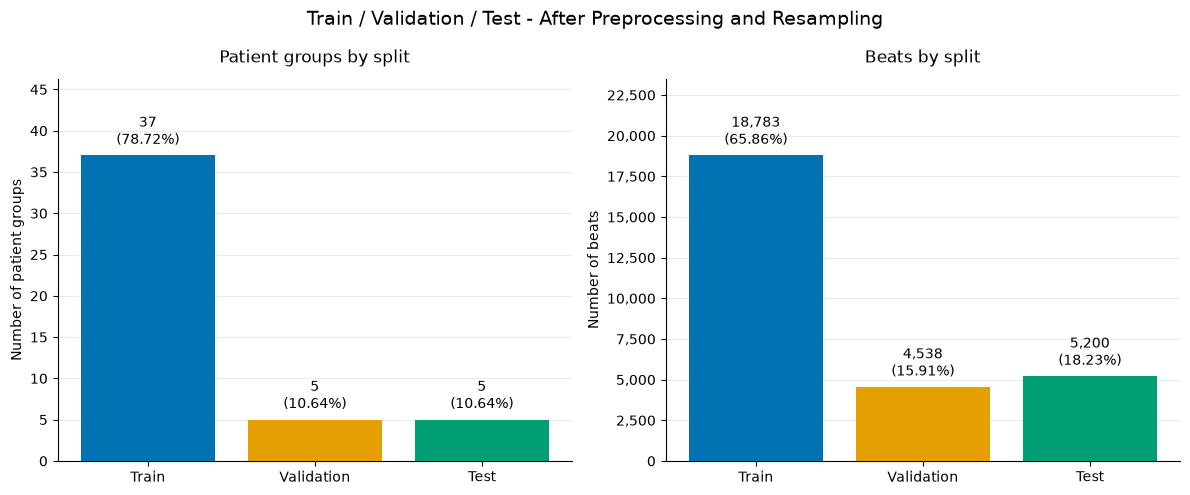

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title, ylabel in zip(
    axes, ['patients', 'beats'], ['Patient groups by split', 'Beats by split'],
    ['Number of patient groups', 'Number of beats'],
):
    values = split_counts[column].to_numpy()
    shares = values / values.sum() * 100
    bars = ax.bar(split_labels, values,
                  color=[split_colors[name] for name in split_order], zorder=3)
    ax.bar_label(bars, labels=[f'{value:,}\n({share:.2f}%)'
                              for value, share in zip(values, shares)], padding=5)
    ax.set_title(title, pad=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values.max() * 1.25, 1))
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Train / Validation / Test - After Preprocessing and Resampling', fontsize=14)
fig.tight_layout()
plt.show()


### Remaining beats in each class by split

Each panel has its own y-axis. Percentages show the share of that class across the three splits.


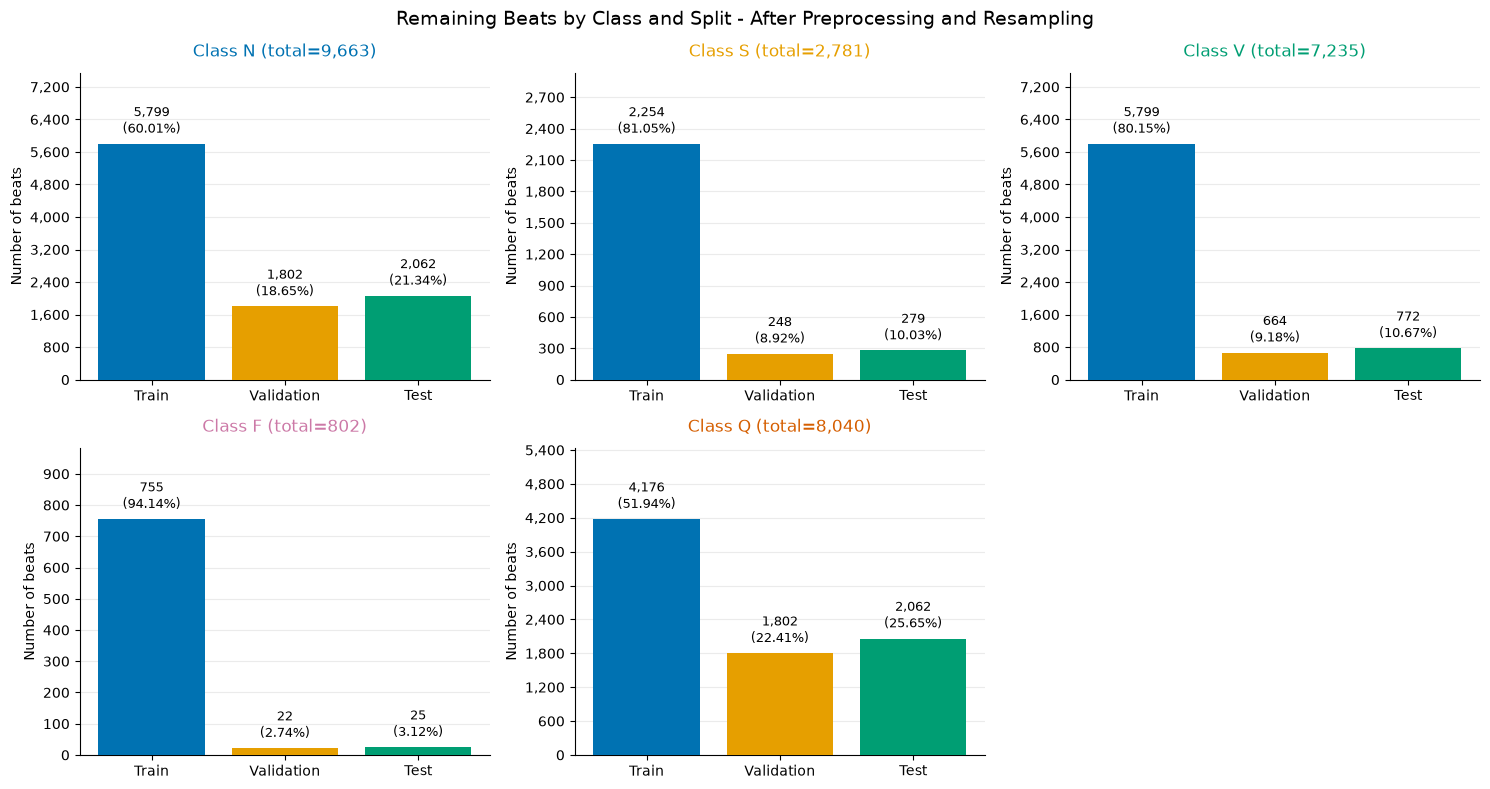

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column, label in zip(axes.flat, class_columns, CLASSES):
    values = split_counts[column].to_numpy()
    class_total = int(values.sum())
    shares = values / class_total * 100 if class_total else np.zeros(len(values))
    bars = ax.bar(split_labels, values,
                  color=[split_colors[name] for name in split_order], zorder=3)
    ax.bar_label(bars, labels=[f'{value:,}\n({share:.2f}%)'
                              for value, share in zip(values, shares)], padding=5, fontsize=9)
    ax.set_title(f'Class {label} (total={class_total:,})', color=class_colors[label], pad=12)
    ax.set_ylabel('Number of beats')
    ax.set_ylim(0, max(values.max() * 1.3, 1))
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
for ax in list(axes.flat)[len(CLASSES):]:
    ax.set_visible(False)
fig.suptitle('Remaining Beats by Class and Split - After Preprocessing and Resampling', fontsize=14)
fig.tight_layout()
plt.show()
